# IT3212 – Assignment 3 – Tasks 5 & 6: Classification and Comparison

This notebook builds on **Task 4 (Feature Selection)**. Task 5 implements and justifies three classification algorithms using the same 18 selected input features and the existing training/validation split.

**Models:** Decision Tree, Naive Bayes and a Neural Network (MLP).

**Target:** `smoking` (`0` = never smoked, `1` = current or former smoker).

**Inputs:** `../data/assignment3/task4_train.csv`, `task4_val.csv`, and `task4_metadata.json`.

The test set is intentionally not loaded at this stage. It is reserved for the final evaluation after model decisions have been made.

## Task 5 – Implement and justify three algorithms

### Imports and data loading

In [11]:
import json
import time
from pathlib import Path

import joblib
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_DIR = Path("../data/assignment3")
RANDOM_STATE = 42

with open(DATA_DIR / "task4_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

TARGET = metadata["target"]
FEATURES = metadata["selected_features"]
SCALE_COLS = metadata["scaling"]["columns"]

train_df = pd.read_csv(DATA_DIR / "task4_train.csv")
val_df = pd.read_csv(DATA_DIR / "task4_val.csv")

X_train = train_df[FEATURES]
y_train = train_df[TARGET]
X_val = val_df[FEATURES]
y_val = val_df[TARGET]

assert len(FEATURES) == 18, "Expected 18 selected features from Task 4."
assert all(c in X_train.columns for c in SCALE_COLS)
assert not X_train.isna().any().any() and not X_val.isna().any().any()
assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}

print(f"Train: {X_train.shape[0]:,} rows, {X_train.shape[1]} features")
print(f"Val:   {X_val.shape[0]:,} rows, {X_val.shape[1]} features")
print(f"Smoking class share in train: {y_train.mean():.3f}")
print(f"Columns to scale for MLP: {len(SCALE_COLS)}")
print(f"Selected features: {FEATURES}")

Train: 787,625 rows, 18 features
Val:   98,453 rows, 18 features
Smoking class share in train: 0.392
Columns to scale for MLP: 17
Selected features: ['sex', 'height', 'hemoglobin', 'weight', 'gamma_GTP', 'serum_creatinine', 'waistline', 'TG_HDL_ratio', 'triglyceride', 'BMI', 'SGOT_ALT', 'AST_ALT_ratio', 'HDL_chole', 'waist_height_ratio', 'cholesterol_ratio', 'LDL_HDL_ratio', 'age', 'SGOT_AST']


### Decision Tree


### Hyperparameter comparison

Decision Tree depth comparison:


,max_depth,actual_depth,train_F1,val_F1,train_accuracy,val_accuracy,fit_seconds
0,3,3,0.7779,0.7776,0.8068,0.8063,3.1152
1,5,5,0.7850,0.7856,0.8094,0.8096,3.6614
2,8,8,0.7849,0.7841,0.8110,0.8101,5.8459
3,12,12,0.7875,0.7792,0.8153,0.8081,8.7941
4,16,16,0.7894,0.7681,0.8205,0.8022,12.0633


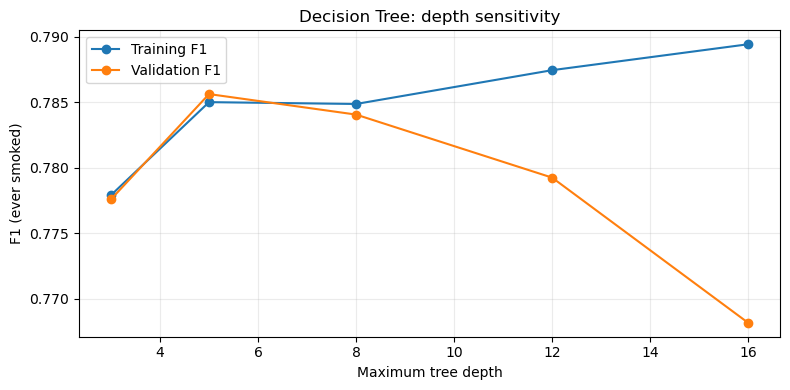

Selected max_depth=5 (validation F1=0.7856)


In [12]:
import matplotlib.pyplot as plt

# Decision Tree sensitivity to maximum depth.
# Compare candidates before fitting the final Decision Tree.
tree_trials = []
for depth in [3, 5, 8, 12, 16]:
    trial = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=50, random_state=RANDOM_STATE
    )
    start = time.perf_counter()
    trial.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    tree_trials.append({
        "max_depth": depth,
        "actual_depth": trial.get_depth(),
        "train_F1": f1_score(y_train, trial.predict(X_train)),
        "val_F1": f1_score(y_val, trial.predict(X_val)),
        "train_accuracy": accuracy_score(y_train, trial.predict(X_train)),
        "val_accuracy": accuracy_score(y_val, trial.predict(X_val)),
        "fit_seconds": elapsed,
    })

tree_tuning_df = pd.DataFrame(tree_trials)
print("Decision Tree depth comparison:")
display(tree_tuning_df.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tree_tuning_df["max_depth"], tree_tuning_df["train_F1"], marker="o", label="Training F1")
ax.plot(tree_tuning_df["max_depth"], tree_tuning_df["val_F1"], marker="o", label="Validation F1")
ax.set(xlabel="Maximum tree depth", ylabel="F1 (ever smoked)", title="Decision Tree: depth sensitivity")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
# Select by external validation F1; for exact ties prefer the shallower tree.
best_tree_row = tree_tuning_df.sort_values(["val_F1", "max_depth"], ascending=[False, True]).iloc[0]
best_tree_depth = int(best_tree_row["max_depth"])
print(f"Selected max_depth={best_tree_depth} (validation F1={best_tree_row['val_F1']:.4f})")


### Final model

In [13]:
decision_tree = DecisionTreeClassifier(
    max_depth=best_tree_depth,
    min_samples_leaf=50,
    random_state=RANDOM_STATE
)

start = time.perf_counter()
decision_tree.fit(X_train, y_train)
tree_train_time = time.perf_counter() - start

print(f"Decision Tree trained in {tree_train_time:.2f} seconds")
print("Tree depth:", decision_tree.get_depth())
print("Number of leaf nodes:", decision_tree.get_n_leaves())


Decision Tree trained in 4.73 seconds
Tree depth: 5
Number of leaf nodes: 32


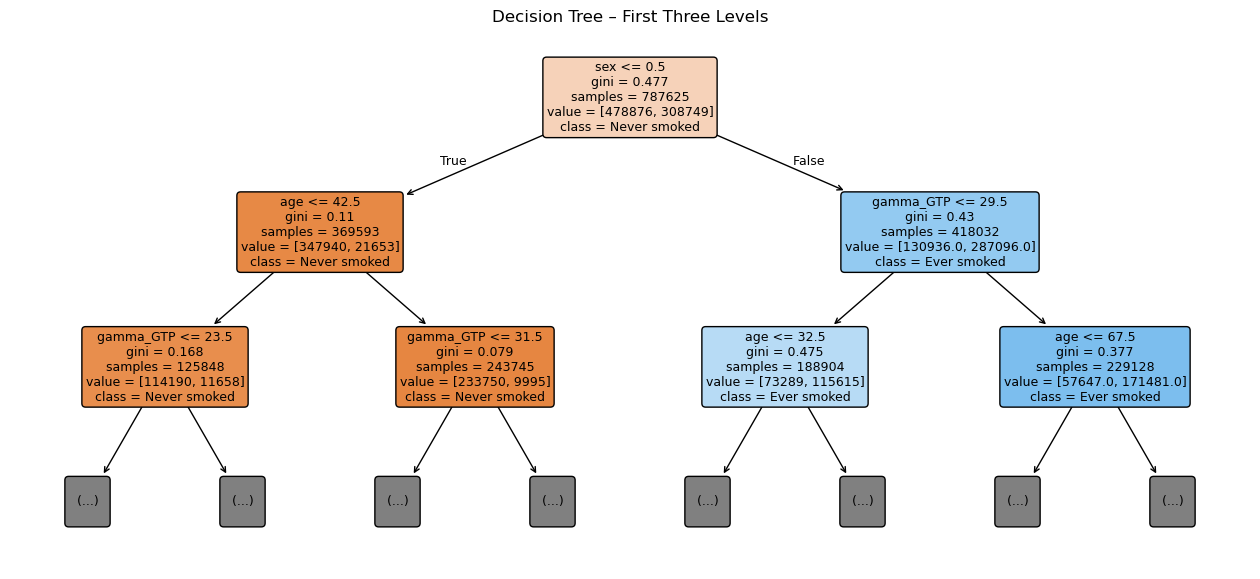

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 7))

plot_tree(
    decision_tree,
    feature_names=X_train.columns,
    class_names=["Never smoked", "Ever smoked"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.title("Decision Tree – First Three Levels")
plt.show()